## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

<pre>



















</pre>

## Create a DataFrame

In [2]:
df = pd.DataFrame({'x1': [2.1, 3.2, 4.1, 1.15, 5.05, 6.1, 7.2, 8.1, np.nan],
                   'x2': [6.45,  9.6 , 10.4 ,  5.9, 12.6 , 16.33, 18.6 , 20.3, 19.5]})

df

,x1,x2
0,2.10,6.45
1,3.20,9.60
2,4.10,10.40
3,1.15,5.90
4,5.05,12.60
5,6.10,16.33
6,7.20,18.60
7,8.10,20.30
8,NaN,19.50


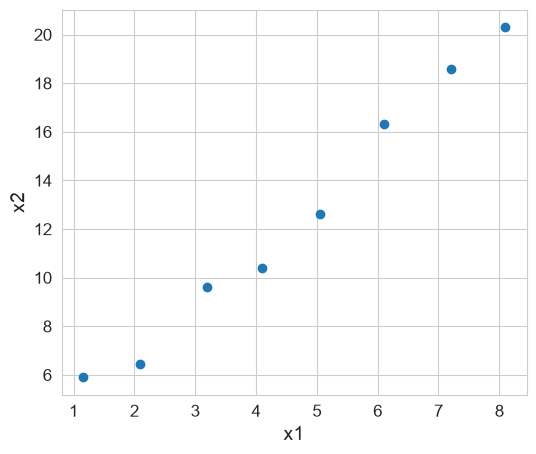

In [3]:
plt.figure(figsize=(6,5))

plt.scatter(df['x1'], df['x2'])

plt.xlabel('x1', fontsize=14)
plt.ylabel('x2', fontsize=14)
plt.tick_params(labelsize=12)
plt.show()

<pre>



















</pre>

## Mean imputation

Use `.fillna` to replace `NaN`s with the mean value in the column

In [4]:
df_mean = df.fillna(df.mean())

df_mean

,x1,x2
0,2.100,6.45
1,3.200,9.60
2,4.100,10.40
3,1.150,5.90
4,5.050,12.60
5,6.100,16.33
6,7.200,18.60
7,8.100,20.30
8,4.625,19.50


Plot the result

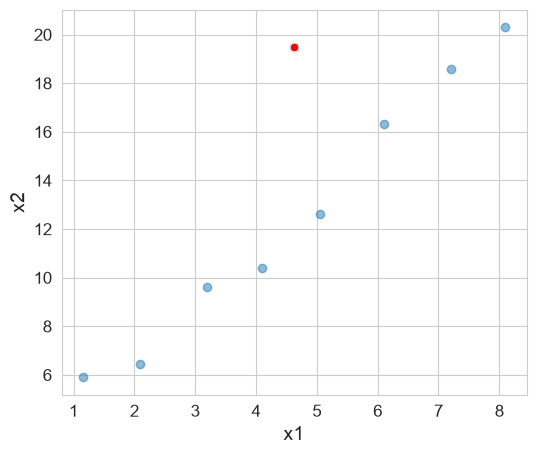

In [5]:
plt.figure(figsize=(6,5))

plt.scatter(df_mean['x1'], df_mean['x2'], alpha=0.5)

sns.scatterplot(data=df_mean[df['x1'].isna()], x='x1', y='x2', color='r')

plt.xlabel('x1', fontsize=14)
plt.ylabel('x2', fontsize=14)
plt.tick_params(labelsize=12)
plt.show()

<pre>



















</pre>

## Median imputation

Use `.fillna` to replace `NaN`s with the median value in the column

In [6]:
df_median = df.fillna(df.median())

df_median

,x1,x2
0,2.100,6.45
1,3.200,9.60
2,4.100,10.40
3,1.150,5.90
4,5.050,12.60
5,6.100,16.33
6,7.200,18.60
7,8.100,20.30
8,4.575,19.50


Plot the result

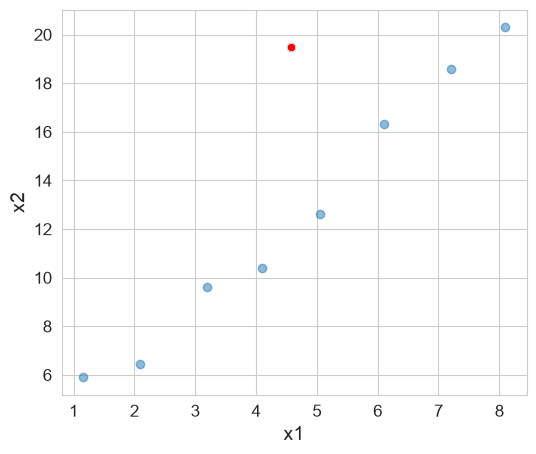

In [7]:
plt.figure(figsize=(6,5))

plt.scatter(df_median['x1'], df_median['x2'], alpha=0.5)

sns.scatterplot(data=df_median[df['x1'].isna()], x='x1', y='x2', color='r')

plt.xlabel('x1', fontsize=14)
plt.ylabel('x2', fontsize=14)
plt.tick_params(labelsize=12)
plt.show()

<pre>



















</pre>

## Mode imputation

Use `.fillna` to replace `NaN`s with the mode value in the column

In [8]:
df_mode = df.fillna(df.mode().iloc[0])

df_mode

,x1,x2
0,2.10,6.45
1,3.20,9.60
2,4.10,10.40
3,1.15,5.90
4,5.05,12.60
5,6.10,16.33
6,7.20,18.60
7,8.10,20.30
8,1.15,19.50


Plot the result

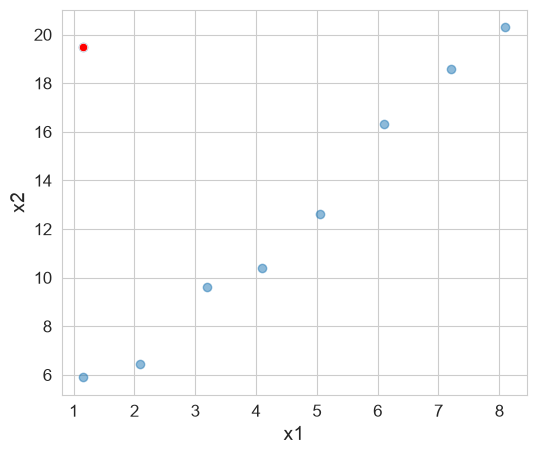

In [9]:
plt.figure(figsize=(6,5))

plt.scatter(df_mode['x1'], df_mode['x2'], alpha=0.5)

sns.scatterplot(data=df_mode[df['x1'].isna()], x='x1', y='x2', color='r')

plt.xlabel('x1', fontsize=14)
plt.ylabel('x2', fontsize=14)
plt.tick_params(labelsize=12)
plt.show()

<pre>



















</pre>

## Iterative imputer

Use an iterative imputer to fill the missing value

In [10]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [11]:
imputer = IterativeImputer()

In [12]:
imputer.fit(df)

,"estimator estimator: estimator object, default=BayesianRidge()The estimator to use at each step of the round-robin imputation.If `sample_posterior=True`, the estimator must support`return_std` in its `predict` method.",None
,"missing_values missing_values: int or np.nan, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to `np.nan`, since `pd.NA` will be converted to `np.nan`.",nan
,"sample_posterior sample_posterior: bool, default=FalseWhether to sample from the (Gaussian) predictive posterior of thefitted estimator for each imputation. Estimator must support`return_std` in its `predict` method if set to `True`. Set to`True` if using `IterativeImputer` for multiple imputations.",False
,"max_iter max_iter: int, default=10Maximum number of imputation rounds to perform before returning theimputations computed during the final round. A round is a singleimputation of each feature with missing values. The stopping criterionis met once `max(abs(X_t - X_{t-1}))/max(abs(X[known_vals])) < tol`,where `X_t` is `X` at iteration `t`. Note that early stopping is onlyapplied if `sample_posterior=False`.",10
,"tol tol: float, default=1e-3Tolerance of the stopping condition.",0.001
,"n_nearest_features n_nearest_features: int, default=NoneNumber of other features to use to estimate the missing values ofeach feature column. Nearness between features is measured usingthe absolute correlation coefficient between each feature pair (afterinitial imputation). To ensure coverage of features throughout theimputation process, the neighbor features are not necessarily nearest,but are drawn with probability proportional to correlation for eachimputed target feature. Can provide significant speed-up when thenumber of features is huge. If `None`, all features will be used.",None
,"initial_strategy initial_strategy: {'mean', 'median', 'most_frequent', 'constant'}, default='mean'Which strategy to use to initialize the missing values. Same as the`strategy` parameter in :class:`~sklearn.impute.SimpleImputer`.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen `strategy=""constant""`, `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types... versionadded:: 1.3",None
,"imputation_order imputation_order: {'ascending', 'descending', 'roman', 'arabic', 'random'}, default='ascending'The order in which the features will be imputed. Possible values:- `'ascending'`: From features with fewest missing values to most.- `'descending'`: From features with most missing values to fewest.- `'roman'`: Left to right.- `'arabic'`: Right to left.- `'random'`: A random order for each round.",'ascending'
,"skip_complete skip_complete: bool, default=FalseIf `True` then features with missing values during :meth:`transform`which did not have any missing values during :meth:`fit` will beimputed with the initial imputation method only. Set to `True` if youhave many features with no missing values at both :meth:`fit` and:meth:`transform` time to save compute.",False
,"min_value min_value: float or array-like of shape (n_features,), default=-np.infMinimum possible imputed value. Broadcast to shape `(n_features,)` ifscalar. If array-like, expects shape `(n_features,)`, one min value foreach feature. The default is `-np.inf`... versionchanged:: 0.23 Added support for array-like.",-inf


In [13]:
df_iterative = imputer.transform(df)

df_iterative = pd.DataFrame(df_iterative, columns=df.columns)

df_iterative

,x1,x2
0,2.100000,6.45
1,3.200000,9.60
2,4.100000,10.40
3,1.150000,5.90
4,5.050000,12.60
5,6.100000,16.33
6,7.200000,18.60
7,8.100000,20.30
8,7.736131,19.50


Plot the result

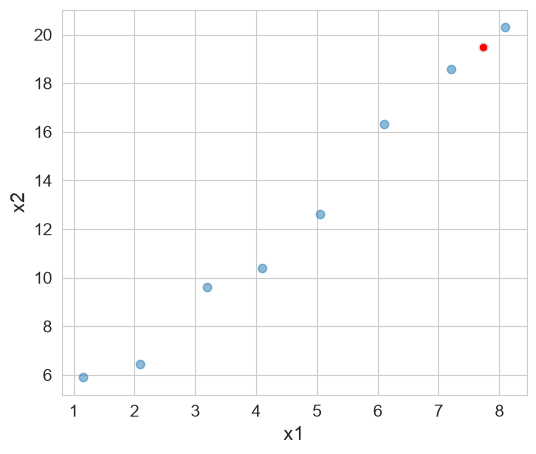

In [14]:
plt.figure(figsize=(6,5))

plt.scatter(df_iterative['x1'], df_iterative['x2'], alpha=0.5)

sns.scatterplot(data=df_iterative[df['x1'].isna()], x='x1', y='x2', color='r')

plt.xlabel('x1', fontsize=14)
plt.ylabel('x2', fontsize=14)
plt.tick_params(labelsize=12)
plt.show()

<pre>



















</pre>

## KNN imputer

In [15]:
from sklearn.impute import KNNImputer

In [16]:
imputer = KNNImputer()

In [17]:
imputer.fit(df)

,"missing_values missing_values: int, float, str, np.nan or None, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to np.nan, since `pd.NA` will be converted to np.nan.",nan
,"n_neighbors n_neighbors: int, default=5Number of neighboring samples to use for imputation.",5
,"weights weights: {'uniform', 'distance'} or callable, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- callable : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.",'uniform'
,"metric metric: {'nan_euclidean'} or callable, default='nan_euclidean'Distance metric for searching neighbors. Possible values:- 'nan_euclidean'- callable : a user-defined function which conforms to the definition of ``func_metric(x, y, *, missing_values=np.nan)``. `x` and `y` corresponds to a row (i.e. 1-D arrays) of `X` and `Y`, respectively. The callable should returns a scalar distance value.",'nan_euclidean'
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto theoutput of the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear on themissing indicator even if there are missing values at transform/testtime.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0`... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['x1','x2']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.``None`` if add_indicator is False.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2


In [18]:
df_knn = imputer.transform(df)
# Since x1 is missing, KNN uses the available x2 value, 19.5, to find the five nearest observations based on x2. 
# Then it takes the average of their x1 values to impute the missing value.

df_knn = pd.DataFrame(df_knn, columns=df.columns)

df_knn

,x1,x2
0,2.10,6.45
1,3.20,9.60
2,4.10,10.40
3,1.15,5.90
4,5.05,12.60
5,6.10,16.33
6,7.20,18.60
7,8.10,20.30
8,6.11,19.50


Plot the result

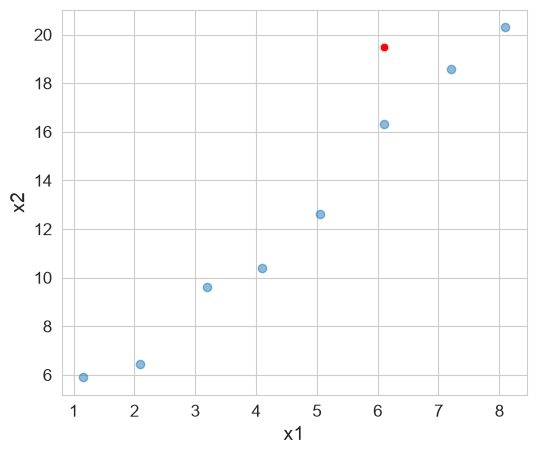

In [19]:
plt.figure(figsize=(6,5))

plt.scatter(df_knn['x1'], df_knn['x2'], alpha=0.5)

sns.scatterplot(data=df_knn[df['x1'].isna()], x='x1', y='x2', color='r')

plt.xlabel('x1', fontsize=14)
plt.ylabel('x2', fontsize=14)
plt.tick_params(labelsize=12)
plt.show()